# Multiobjective Optimization: Pareto Dominance and the Pareto Front

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L12/L12_pareto_dominance_and_front.ipynb)
### MECH 559 - Systems Optimization - L12
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the *Problem formulation* and *Pareto optimality* sections of the lecture.
Until now every problem had **one** objective, and its solution was one point. Real design problems
rarely do: a lighter wing is usually a more flexible one, a cheaper process a slower one. A
multiobjective optimization problem (MOP)

$$
\\min_{\\mathbf{x} \\in \\Omega}\\ F(\\mathbf{x}) = \\big(f^{(1)}(\\mathbf{x}), f^{(2)}(\\mathbf{x}), \\ldots, f^{(p)}(\\mathbf{x})\\big)
$$

asks for **all the best trade-offs** instead. Before using an algorithm that builds them (next
notebooks), we make the definitions of the slides concrete on a problem whose answer we know exactly.

## Learning objectives

1. Apply the dominance relations (weak dominance, dominance, indifference) to points in objective space.
2. Extract the non-dominated points of a set, and relate the Pareto set $\\Omega_{\\mathcal{P}}$ (decision space)
   to the Pareto front $F_{\\mathcal{P}}$ (objective space).
3. Measure the quality of an approximate front with the hypervolume indicator.
4. Explain why adding the objectives with weights cannot find the whole front of a non-convex problem.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import minimize

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"sample": "#9AA0A6", "front": "#D1495B", "exact": "#1D5FA8", "ws": "#2A9D5C", "eps": "#EDAE49"}
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
rng = np.random.default_rng(559)

---
## 1. A problem with a known answer

Two objectives on $\mathbf{x} \in [-2, 2]^2$:

$$
f^{(1)}(\mathbf{x}) = \|\mathbf{x}\|^2, \qquad f^{(2)}(\mathbf{x}) = \|\mathbf{x} - \mathbf{1}\|^2 .
$$

$f^{(1)}$ alone is minimized at $\mathbf{x} = (0, 0)$, $f^{(2)}$ alone at $\mathbf{x} = (1, 1)$. No point
minimizes both: moving from one minimizer toward the other decreases one objective and increases the
other. The objectives are **contradictory**, the typical situation of the slides.

In [2]:
def sphere_pair(x):
    x = np.asarray(x, dtype=float)
    return np.array([np.sum(x ** 2), np.sum((x - 1.0) ** 2)])


LB, UB = np.array([-2.0, -2.0]), np.array([2.0, 2.0])
for name, x in [("minimizer of f1", [0, 0]), ("minimizer of f2", [1, 1]), ("halfway", [0.5, 0.5])]:
    print(f"{name:16s} x = {x}  ->  F(x) = {sphere_pair(x)}")

minimizer of f1  x = [0, 0]  ->  F(x) = [0. 2.]
minimizer of f2  x = [1, 1]  ->  F(x) = [2. 0.]
halfway          x = [0.5, 0.5]  ->  F(x) = [0.5 0.5]


The **ideal point** $(\min f^{(1)}, \min f^{(2)}) = (0, 0)$ collects the best value of each objective. It
is not attainable: no single $\mathbf{x}$ has $F(\mathbf{x}) = (0, 0)$. That is what "there is usually no
vector that minimizes all objectives" means.

---
## 2. Pareto dominance

For two points $x_1, x_2 \in \Omega$ (slide *Pareto dominance*):

- $x_1 \preceq x_2$, $x_1$ **weakly dominates** $x_2$: $f_i(x_1) \le f_i(x_2)$ for every objective $i$;
- $x_1 \prec x_2$, $x_1$ **dominates** $x_2$: $x_1 \preceq x_2$ and $f_{i_0}(x_1) < f_{i_0}(x_2)$ for at least one $i_0$;
- $x_1 \sim x_2$, they are **indifferent**: neither dominates the other.

The three functions below are the definitions, word for word. They act on objective vectors, because
dominance only depends on $F(x)$.

In [3]:
def weakly_dominates(fa, fb):
    return bool(np.all(np.asarray(fa) <= np.asarray(fb)))


def dominates(fa, fb):
    return weakly_dominates(fa, fb) and bool(np.any(np.asarray(fa) < np.asarray(fb)))


def relation(fa, fb):
    if dominates(fa, fb):
        return "a dominates b"
    if dominates(fb, fa):
        return "b dominates a"
    if np.array_equal(fa, fb):
        return "equal"
    return "indifferent"


f_x1 = np.array([0.5, 0.5])
tests = {"(0.5, 0.6)": [0.5, 0.6], "(0.6, 0.6)": [0.6, 0.6], "(0.3, 0.6)": [0.3, 0.6], "(0.4, 0.4)": [0.4, 0.4]}
pd.DataFrame([{"F(x2)": k, "x1 weakly dominates x2": weakly_dominates(f_x1, v),
               "x1 dominates x2": dominates(f_x1, v), "relation (a = x1, b = x2)": relation(f_x1, v)}
              for k, v in tests.items()])

,F(x2),x1 weakly dominates x2,x1 dominates x2,"relation (a = x1, b = x2)"
0,"(0.5, 0.6)",True,True,a dominates b
1,"(0.6, 0.6)",True,True,a dominates b
2,"(0.3, 0.6)",False,False,indifferent
3,"(0.4, 0.4)",False,False,b dominates a


These are the four points of the animated slide. Note the first row: $(0.5, 0.6)$ is equal to $x_1$ in
$f_1$ and worse in $f_2$, so it is dominated. A tie in one objective is enough as long as the other
objective is strictly worse.

Around any point, the objective plane splits into the four zones of the slide:

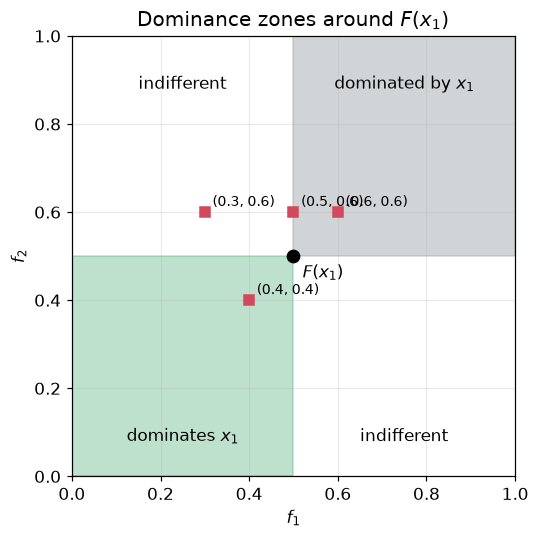

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.add_patch(mpatches.Rectangle(f_x1, 0.5, 0.5, color="#9AA0A6", alpha=0.45))
ax.add_patch(mpatches.Rectangle((0, 0), 0.5, 0.5, color="#2A9D5C", alpha=0.30))
ax.plot(*f_x1, "o", color="k", ms=8, zorder=5)
ax.annotate("$F(x_1)$", f_x1, textcoords="offset points", xytext=(6, -14))
for (x, y), txt in [((0.75, 0.88), "dominated by $x_1$"), ((0.25, 0.08), "dominates $x_1$"),
                    ((0.75, 0.08), "indifferent"), ((0.25, 0.88), "indifferent")]:
    ax.text(x, y, txt, ha="center")
for name, v in tests.items():
    ax.plot(*v, "s", ms=6, color=COLORS["front"])
    ax.annotate(name, v, textcoords="offset points", xytext=(5, 4), fontsize=9)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="$f_1$", ylabel="$f_2$", title="Dominance zones around $F(x_1)$")
plt.show()

> **Checkpoint 1.** A third point has $F(x_3) = (0.2, 0.9)$. Which zone is it in? Does that make $x_3$ a
> better design than $x_1$? *Answer:* the top-left indifference zone. Neither design is better: $x_3$ is
> better in $f_1$, worse in $f_2$. Only the designer's preferences can rank them, which is why a MOP returns
> a set of trade-offs and not a single answer.

---
## 3. Non-dominated points, the Pareto set and the Pareto front

A point $x^* \in \Omega$ is **Pareto optimal** if no $x \in \Omega$ dominates it. The Pareto optimal
points form the **Pareto set** $\Omega_{\mathcal{P}}$; their images form the **Pareto front**
$F_{\mathcal{P}} = F(\Omega_{\mathcal{P}})$.

In practice we never have all of $\Omega$, only the points we evaluated. The non-dominated points of a
finite set are an **approximation** of the Pareto set. The filter below compares every point with all
the others: it is exactly the test of the definition, applied to a sample.

In [5]:
def nondominated(F):
    """Boolean mask of the rows of F (n_points x p) that no other row dominates."""
    F = np.asarray(F, dtype=float)
    mask = np.ones(len(F), dtype=bool)
    for i in range(len(F)):
        dominated_by = np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)
        mask[i] = not dominated_by.any()
    return mask


X = LB + rng.random((2000, 2)) * (UB - LB)          # 2000 random designs
F = np.array([sphere_pair(x) for x in X])
nd = nondominated(F)
print(f"{nd.sum()} of {len(F)} random designs are non-dominated")

38 of 2000 random designs are non-dominated


For this problem the exact answer is known. Setting $\nabla f^{(1)} = -\lambda \nabla f^{(2)}$ shows that the
Pareto set is the **segment** between the two minimizers, $\mathbf{x}(t) = t\,(1, 1)$ for $t \in [0, 1]$,
and the Pareto front is the curve $\big(2t^2,\ 2(1-t)^2\big)$. The figure is the slide
*Pareto optimal set and Pareto front* for this problem: the decision space on the left, its image on the right.

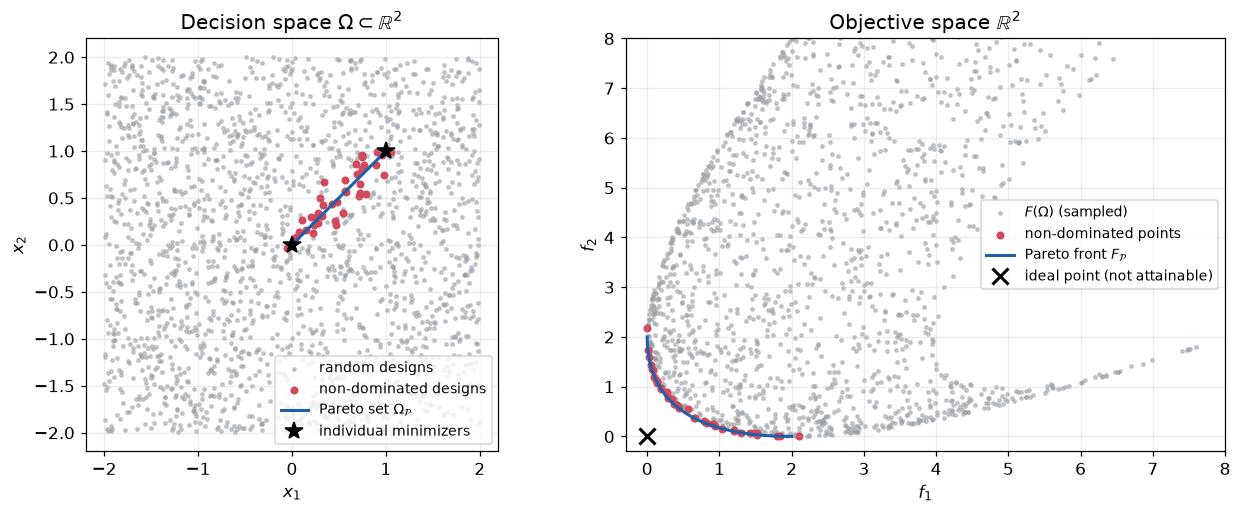

In [6]:
t = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
ax.scatter(*X[~nd].T, s=5, color=COLORS["sample"], alpha=0.5, label="random designs")
ax.scatter(*X[nd].T, s=18, color=COLORS["front"], label="non-dominated designs")
ax.plot(t, t, color=COLORS["exact"], lw=2, label=r"Pareto set $\Omega_\mathcal{P}$")
ax.plot([0, 1], [0, 1], "k*", ms=12, label="individual minimizers")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title=r"Decision space $\Omega \subset \mathbb{R}^2$", aspect="equal")
ax.legend(loc="lower right", fontsize=9)
ax = axes[1]
ax.scatter(*F[~nd].T, s=5, color=COLORS["sample"], alpha=0.5, label=r"$F(\Omega)$ (sampled)")
ax.scatter(*F[nd].T, s=18, color=COLORS["front"], label="non-dominated points")
ax.plot(2 * t ** 2, 2 * (1 - t) ** 2, color=COLORS["exact"], lw=2, label=r"Pareto front $F_\mathcal{P}$")
ax.plot(0, 0, "kx", ms=10, mew=2, label="ideal point (not attainable)")
ax.set(xlabel="$f_1$", ylabel="$f_2$", title=r"Objective space $\mathbb{R}^2$", xlim=(-0.3, 8), ylim=(-0.3, 8))
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

What to notice:

- The Pareto front is the **lower-left boundary** of $F(\Omega)$: for minimization, no point of $F(\Omega)$
  lies below and to the left of it.
- The non-dominated random designs lie **close to** the Pareto set, but none is exactly on it. Being
  non-dominated in a sample is not the same as being Pareto optimal.
- 2000 random evaluations gave only a few dozen useful points, and the problem has only 2 variables.
  With more variables random sampling gets much worse. Algorithms such as DMulti-MADS place their
  evaluations near the front on purpose.

---
## 4. Measuring an approximate front: the hypervolume

To compare two approximations of a front we need a number. The **hypervolume** $HV(A, r)$ of a set $A$
of non-dominated points is the area (volume for $p > 2$) of the region that $A$ dominates, up to a
**reference point** $r$ that is worse than every point of interest. A larger hypervolume means a front
that is closer to the true front **and** better spread along it. In two dimensions it is a sum of
rectangles:

In [7]:
def hypervolume_2d(F, ref):
    """Area dominated by the points of F (n x 2) and bounded by the reference point ref."""
    F = np.asarray(F, dtype=float).reshape(-1, 2)
    F = F[np.all(F < ref, axis=1)]
    if len(F) == 0:
        return 0.0
    F = F[nondominated(F)]
    F = F[np.argsort(F[:, 0])]          # f1 increasing, hence f2 decreasing
    hv, f2_prev = 0.0, ref[1]
    for f1, f2 in F:
        hv += (ref[0] - f1) * (f2_prev - f2)
        f2_prev = f2
    return hv


REF = np.array([2.5, 2.5])              # slightly worse than the nadir point (2, 2) of the front
s = np.linspace(0, 2, 20001)
HV_EXACT = np.trapezoid(REF[1] - (np.sqrt(2) - np.sqrt(s)) ** 2, s) + (REF[0] - 2) * REF[1]
print(f"exact hypervolume of the Pareto front for r = {REF}: {HV_EXACT:.4f}")

exact hypervolume of the Pareto front for r = [2.5 2.5]: 5.5833


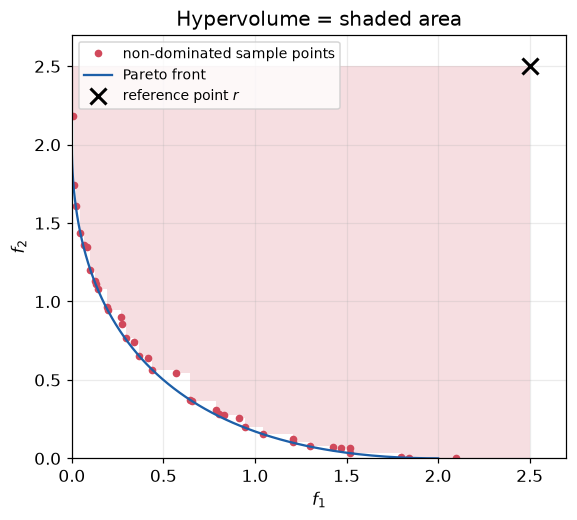

In [8]:
F_nd = F[nd][np.argsort(F[nd][:, 0])]
fig, ax = plt.subplots(figsize=(5.8, 5))
f2_prev = REF[1]
for f1, f2 in F_nd[np.all(F_nd < REF, axis=1)]:
    ax.add_patch(mpatches.Rectangle((f1, f2), REF[0] - f1, f2_prev - f2, color=COLORS["front"], alpha=0.18, lw=0))
    f2_prev = f2
ax.plot(*F_nd.T, "o", ms=4, color=COLORS["front"], label="non-dominated sample points")
ax.plot(2 * t ** 2, 2 * (1 - t) ** 2, color=COLORS["exact"], lw=1.5, label="Pareto front")
ax.plot(*REF, "kx", ms=10, mew=2, label="reference point $r$")
ax.set(xlim=(0, 2.7), ylim=(0, 2.7), xlabel="$f_1$", ylabel="$f_2$", title="Hypervolume = shaded area")
ax.legend(fontsize=9)
plt.show()

In [9]:
rows = []
for n in [20, 100, 500, 2000, 10000]:
    Xn = LB + rng.random((n, 2)) * (UB - LB)
    Fn = np.array([sphere_pair(x) for x in Xn])
    hv = hypervolume_2d(Fn, REF)
    rows.append(dict(evaluations=n, non_dominated=int(nondominated(Fn).sum()), hypervolume=hv,
                     fraction_of_exact=hv / HV_EXACT))
pd.DataFrame(rows).set_index("evaluations")

,non_dominated,hypervolume,fraction_of_exact
evaluations,,,
20,2,3.71596,0.665545
100,7,5.02794,0.900526
500,21,5.37104,0.961978
2000,37,5.50449,0.985879
10000,119,5.55519,0.99496


The hypervolume rises toward the exact value as the sample grows, but slowly: the last few percent cost
thousands of evaluations. The hypervolume is the score we use in the next notebooks to compare
algorithms at the same budget.

The reference point matters. With $r = (2.5, 2.5)$ the whole front counts. With a tighter $r$, only the
part of the front inside the box $[0, r_1] \times [0, r_2]$ counts. That is one way to tell a solver
which part of the front interests you, the idea of a **zone of interest**.

> **Checkpoint 2.** Two algorithms return fronts $A$ and $B$ with $HV(A, r) > HV(B, r)$. Can you conclude
> that every point of $B$ is dominated by a point of $A$? *Answer:* no. The hypervolume is one number: $A$
> may be better on average and still miss a region where $B$ has points. The converse holds: if every
> point of $B$ is weakly dominated by $A$, then $HV(A, r) \ge HV(B, r)$.

---
## 5. Why not just add the objectives?

The classical shortcut is a **weighted sum**: choose $w \in [0, 1]$, minimize the single objective
$w f^{(1)} + (1 - w) f^{(2)}$ with any single-objective optimizer, and repeat for several $w$. Each
solution is Pareto optimal. The question is whether the solutions **cover** the front.

We try it on the sphere pair and on the **Fonseca-Fleming** problem (unconstrained, $\mathbf{x} \in [-4, 4]^2$):

$$
f^{(1)}(\mathbf{x}) = 1 - \exp\Big(-\sum_{i=1}^{2}\big(x_i - \tfrac{1}{\sqrt 2}\big)^2\Big), \qquad
f^{(2)}(\mathbf{x}) = 1 - \exp\Big(-\sum_{i=1}^{2}\big(x_i + \tfrac{1}{\sqrt 2}\big)^2\Big).
$$

Its Pareto set is again a segment, $x_1 = x_2 = s \in [-1/\sqrt 2, 1/\sqrt 2]$, but its front is
**non-convex**: it bulges toward the upper right. Each weighted sum keeps the best of 10 SLSQP starts,
so that a bad start does not blur the result.

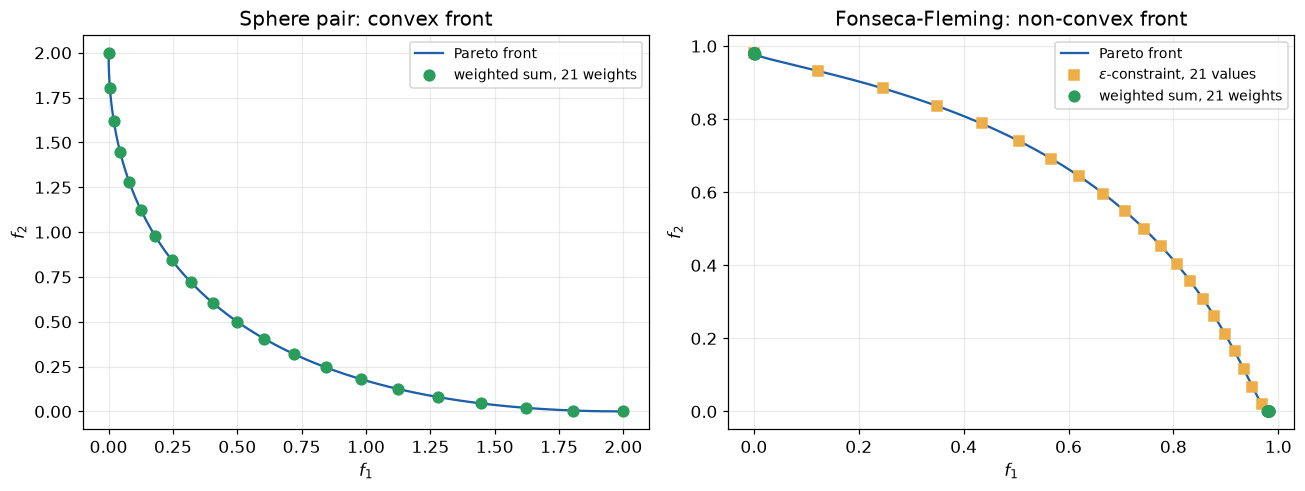

weighted-sum solutions away from the two ends (0.05 < f1, f2 < 0.95): 0 of 21


In [10]:
def fonseca_fleming(x):
    x = np.asarray(x, dtype=float)
    a = 1.0 / np.sqrt(len(x))
    return np.array([1 - np.exp(-np.sum((x - a) ** 2)), 1 - np.exp(-np.sum((x + a) ** 2))])


def weighted_sum(F, lb, ub, weights, n_starts=10, seed=0):
    rs = np.random.default_rng(seed)
    out = []
    for w in weights:
        best = None
        for _ in range(n_starts):
            x0 = lb + rs.random(len(lb)) * (ub - lb)
            r = minimize(lambda x: w * F(x)[0] + (1 - w) * F(x)[1], x0, method="SLSQP",
                         bounds=list(zip(lb, ub)), options={"ftol": 1e-12, "maxiter": 300})
            if best is None or r.fun < best.fun:
                best = r
        out.append(F(best.x))
    return np.array(out)


def eps_constraint(F, lb, ub, eps_values, n_starts=10, seed=0):
    """min f1 subject to f2 <= eps: one constrained optimization per point of the front."""
    rs = np.random.default_rng(seed)
    out = []
    for eps in eps_values:
        best = None
        for _ in range(n_starts):
            x0 = lb + rs.random(len(lb)) * (ub - lb)
            r = minimize(lambda x: F(x)[0], x0, method="SLSQP", bounds=list(zip(lb, ub)),
                         constraints=[{"type": "ineq", "fun": lambda x: eps - F(x)[1]}],
                         options={"ftol": 1e-12, "maxiter": 300})
            if r.success and F(r.x)[1] <= eps + 1e-6 and (best is None or r.fun < best.fun):
                best = r
        if best is not None:
            out.append(F(best.x))
    return np.array(out)


W = np.linspace(0, 1, 21)
LB_FF, UB_FF = np.array([-4.0, -4.0]), np.array([4.0, 4.0])
ws_sphere = weighted_sum(sphere_pair, LB, UB, W)
ws_ff = weighted_sum(fonseca_fleming, LB_FF, UB_FF, W)
eps_ff = eps_constraint(fonseca_fleming, LB_FF, UB_FF, np.linspace(0.02, 0.98, 21))
s_ff = np.linspace(-1, 1, 300) / np.sqrt(2)
front_ff = np.array([fonseca_fleming([v, v]) for v in s_ff])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(2 * t ** 2, 2 * (1 - t) ** 2, color=COLORS["exact"], lw=1.5, label="Pareto front")
axes[0].plot(*ws_sphere.T, "o", color=COLORS["ws"], ms=7, label="weighted sum, 21 weights")
axes[0].set(xlabel="$f_1$", ylabel="$f_2$", title="Sphere pair: convex front")
axes[1].plot(*front_ff.T, color=COLORS["exact"], lw=1.5, label="Pareto front")
axes[1].plot(*eps_ff.T, "s", color=COLORS["eps"], ms=6, label=r"$\varepsilon$-constraint, 21 values")
axes[1].plot(*ws_ff.T, "o", color=COLORS["ws"], ms=7, label="weighted sum, 21 weights")
axes[1].set(xlabel="$f_1$", ylabel="$f_2$", title="Fonseca-Fleming: non-convex front")
for ax in axes:
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
inside = np.all((ws_ff > 0.05) & (ws_ff < 0.95), axis=1)
print(f"weighted-sum solutions away from the two ends (0.05 < f1, f2 < 0.95): {inside.sum()} of {len(W)}")

What to notice:

- On the **convex** front the weighted sum works: the 21 weights give 21 points along the front. They are
  not evenly spaced, because equal steps in $w$ are not equal steps along the front.
- On the **non-convex** front the weighted sum finds only the two ends. For every $w$, the line
  $w f_1 + (1 - w) f_2 = c$ touches the front first at an extreme point. Points in the bulge are Pareto
  optimal, but **no** weight makes them the minimizer.
- The $\varepsilon$-constraint method ($\min f_1$ s.t. $f_2 \le \varepsilon$) recovers the whole front.
  It costs one constrained optimization per point, and it needs a solver that handles constraints well.

Both scalarizations solve **many** single-objective problems to draw **one** front, and with a
gradient-based solver they need derivatives. DMulti-MADS (next notebook) works with blackboxes, needs no
weights, and builds the whole list of non-dominated points in **one** run.

---
## Exercises

1. **Three objectives.** Add $f^{(3)}(\mathbf{x}) = \|\mathbf{x} - (1, -1)\|^2$ to the sphere pair. What is the
   Pareto set now? (Hint: plot the non-dominated designs of a random sample in the decision space.)
2. **Dominance is not a total order.** Draw 50 random points in $[0, 1]^2$. How many pairs are
   indifferent? How many are comparable? Repeat in $[0, 1]^5$ (five objectives). What happens to the
   share of non-dominated points, and what does it mean for algorithms with many objectives?
3. **Reference point.** Recompute the hypervolume table with $r = (1, 1)$ and with $r = (10, 10)$. Which part
   of the front does each choice reward?
4. **Even spacing.** Change the weights of the weighted sum on the sphere pair so that the 21 points are
   evenly spaced along the front. (Hint: write the minimizer as a function of $w$.)

---
## Takeaways

1. A MOP has a **set** of solutions: the Pareto set in decision space, the Pareto front in objective
   space. The ideal point is usually not attainable.
2. $x_1$ dominates $x_2$ if it is no worse in every objective and strictly better in one. Indifferent
   points can only be ranked by the designer's preferences.
3. The non-dominated points of a sample approximate the Pareto set. The hypervolume, for a chosen
   reference point, measures how good the approximation is.
4. Weighted sums miss the non-convex parts of a front, and every scalarization needs many
   single-objective runs. This motivates dominance-based algorithms such as DMulti-MADS.